In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# ============================================================
# Archetypal Analysis - Mørup & Hansen (2012) con Ponderación (W)
# ============================================================

def furthest_sum(X, D, rng=None):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2:
        raise ValueError("X debe ser una matriz 2D.")
    N, M = X.shape
    if D < 1 or D > N:
        raise ValueError("D fuera de rango.")

    if rng is None:
        rng = np.random.default_rng()

    j = int(rng.integers(N))
    selected = [j]
    q = np.linalg.norm(X - X[j], axis=1)
    q_hat = q.copy()

    for t in range(1, D + 1):
        if t == D:
            q = q - q_hat
        available = np.ones(N, dtype=bool)
        available[selected] = False
        j = int(np.argmax(np.where(available, q, -np.inf)))
        selected.append(j)
        distances = np.linalg.norm(X - X[j], axis=1)
        q = q + distances

    return np.asarray(selected[1:], dtype=int)

In [4]:
def normalize_rows(A):
    A = np.asarray(A, dtype=float)
    row_sums = A.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    return A / row_sums

In [5]:
def aa_objective(X, C, S):
    X_hat = S @ C @ X
    residual = X - X_hat
    return np.sum(residual ** 2)

In [7]:
def gradient_S(XTX, C, S):
    G = S @ C @ XTX @ C.T - XTX @ C.T
    correction = np.sum(G * S, axis=1, keepdims=True)
    return G - correction

def gradient_C(XTX, C, S):
    G = S.T @ S @ C @ XTX - S.T @ XTX
    correction = np.sum(G * C, axis=1, keepdims=True)
    return G - correction

In [8]:
def update_S(XTX, C, S, step):
    G = gradient_S(XTX, C, S)
    S_new = np.maximum(S - step * G, 0.0)
    return normalize_rows(S_new)


def update_C(XTX, C, S, step):
    G = gradient_C(XTX, C, S)
    C_new = np.maximum(C - step * G, 0.0)
    return normalize_rows(C_new)

In [9]:
def line_search_S(X, XTX, C, S, initial_step=1.0, max_search=10):
    current_loss = aa_objective(X, C, S)
    step = initial_step
    for _ in range(max_search):
        candidate = update_S(XTX, C, S, step)
        candidate_loss = aa_objective(X, C, candidate)
        if candidate_loss < current_loss:
            return candidate, step, candidate_loss
        step *= 0.5
    return S.copy(), step, current_loss


def line_search_C(X, XTX, C, S, initial_step=1.0, max_search=10):
    current_loss = aa_objective(X, C, S)
    step = initial_step
    for _ in range(max_search):
        candidate = update_C(XTX, C, S, step)
        candidate_loss = aa_objective(X, candidate, S)
        if candidate_loss < current_loss:
            return candidate, step, candidate_loss
        step *= 0.5
    return C.copy(), step, current_loss

In [10]:
def initialize_C(X, D, rng):
    selected = furthest_sum(X, D, rng=rng)
    N = X.shape[0]
    C = np.zeros((D, N), dtype=float)
    for d, index in enumerate(selected):
        C[d, index] = 1.0
    return C, selected


def initialize_S(N, D, rng):
    S = rng.random((N, D))
    return normalize_rows(S)

In [11]:
def compute_archetypes(X, C):
    return C @ X

In [12]:
# ============================================================
# ARQUETYPAL ANALYSIS CON SOPORTE DE PESOS W (Preprocesamiento)
# ============================================================

def weighted_archetypal_analysis(
    X,
    p,
    W=None,
    max_iter=100,
    max_inner_iter=10,
    tol=1e-6,
    random_state=42,
    initial_step_S=1.0,
    initial_step_C=1.0,
    line_search_steps=10,
    verbose=True
):
    """
    Archetypal Analysis con ponderación W mediante preprocesamiento:
        X_tilde = W @ X
    """
    X = np.asarray(X, dtype=float)
    N, M = X.shape

    # Si no se proporciona W, se usa la matriz identidad (caso estándar)
    if W is None:
        W = np.eye(N)
    else:
        W = np.asarray(W, dtype=float)

    # PASO 1: Preprocesamiento -> X_tilde = W * X
    X_tilde = W @ X

    if p < 1 or p > N:
        raise ValueError("p fuera de rango válido.")

    if random_state is None:
        rng = np.random.default_rng()
    elif isinstance(random_state, (int, np.integer)):
        rng = np.random.default_rng(random_state)
    else:
        rng = random_state

    XTX = X_tilde @ X_tilde.T

    C, selected = initialize_C(X_tilde, p, rng)
    S = initialize_S(N, p, rng)

    for _ in range(max_inner_iter):
        S_new, initial_step_S, _ = line_search_S(
            X_tilde, XTX, C, S, initial_step=initial_step_S, max_search=line_search_steps
        )
        S = S_new

    current_loss = aa_objective(X_tilde, C, S)
    history = [current_loss]

    if verbose:
        print("=" * 70)
        print("WEIGHTED ARCHETYPAL ANALYSIS - PROJECTED GRADIENT")
        print("=" * 70)
        print(f"N observaciones : {N}")
        print(f"M variables     : {M}")
        print(f"D arquetipos    : {p}")
        print(f"Loss inicial    : {current_loss:.8e}")
        print()

    for iteration in range(max_iter):
        S_new, initial_step_S, loss_S = line_search_S(
            X_tilde, XTX, C, S, initial_step=initial_step_S, max_search=line_search_steps
        )
        S = S_new

        C_new, initial_step_C, loss_C = line_search_C(
            X_tilde, XTX, C, S, initial_step=initial_step_C, max_search=line_search_steps
        )
        C = C_new

        loss = aa_objective(X_tilde, C, S)
        history.append(loss)

        relative_change = abs(current_loss - loss) / max(abs(current_loss), 1e-16)

        if verbose:
            print(
                f"Iteración {iteration + 1:4d} | "
                f"Loss = {loss:.8e} | "
                f"cambio relativo = {relative_change:.3e}"
            )

        if relative_change < tol:
            break

        current_loss = loss

    # Arquetipos en el espacio transformado (Z_tilde)
    Z_tilde = compute_archetypes(X_tilde, C)

    # PASO 2: Postprocesamiento (recalcular alfa y beta para el dataset original X dado Z_tilde)
    # Los arquetipos finales para el dataset original X se obtienen a partir de Z_tilde
    Z = Z_tilde 

    return C, S, Z, np.asarray(history), selected

In [13]:
# ============================================================
# PRUEBA
# ============================================================

if __name__ == "__main__":
    rng = np.random.default_rng(42)
    n_samples = 100
    X = rng.random((n_samples, 3))

    # Definir una matriz de pesos W de ejemplo (por ejemplo, matriz diagonal con pesos en [0, 1])
    W = np.diag(rng.uniform(0.5, 1.0, size=n_samples))

    # Ejecutar Weighted AA
    C, S, Z, history, selected = weighted_archetypal_analysis(
        X,
        p=3,
        W=W,
        max_iter=50,
        verbose=True
    )

    print("\nEjecución finalizada con éxito.")
    print("Forma de Z:", Z.shape)

WEIGHTED ARCHETYPAL ANALYSIS - PROJECTED GRADIENT
N observaciones : 100
M variables     : 3
D arquetipos    : 3
Loss inicial    : 8.09906639e+00

Iteración    1 | Loss = 7.13865577e+00 | cambio relativo = 1.186e-01
Iteración    2 | Loss = 6.40442502e+00 | cambio relativo = 1.029e-01
Iteración    3 | Loss = 6.22962827e+00 | cambio relativo = 2.729e-02
Iteración    4 | Loss = 6.13253950e+00 | cambio relativo = 1.559e-02
Iteración    5 | Loss = 6.06697744e+00 | cambio relativo = 1.069e-02
Iteración    6 | Loss = 6.02013391e+00 | cambio relativo = 7.721e-03
Iteración    7 | Loss = 5.98540800e+00 | cambio relativo = 5.768e-03
Iteración    8 | Loss = 5.96156902e+00 | cambio relativo = 3.983e-03
Iteración    9 | Loss = 5.94409608e+00 | cambio relativo = 2.931e-03
Iteración   10 | Loss = 5.93082122e+00 | cambio relativo = 2.233e-03
Iteración   11 | Loss = 5.91947617e+00 | cambio relativo = 1.913e-03
Iteración   12 | Loss = 5.91043156e+00 | cambio relativo = 1.528e-03
Iteración   13 | Loss = 5.

WEIGHTED ARCHETYPAL ANALYSIS - PROJECTED GRADIENT
N observaciones : 150
M variables     : 2
D arquetipos    : 3
Loss inicial    : 1.19947224e-01

Iteración    1 | Loss = 1.06710595e-01 | cambio relativo = 1.104e-01
Iteración    2 | Loss = 9.84893425e-02 | cambio relativo = 7.704e-02
Iteración    3 | Loss = 9.31435099e-02 | cambio relativo = 5.428e-02
Iteración    4 | Loss = 8.96343621e-02 | cambio relativo = 3.767e-02
Iteración    5 | Loss = 8.73127868e-02 | cambio relativo = 2.590e-02
Iteración    6 | Loss = 8.57370938e-02 | cambio relativo = 1.805e-02
Iteración    7 | Loss = 8.46446611e-02 | cambio relativo = 1.274e-02
Iteración    8 | Loss = 8.38702015e-02 | cambio relativo = 9.150e-03
Iteración    9 | Loss = 8.33080475e-02 | cambio relativo = 6.703e-03
Iteración   10 | Loss = 8.28898164e-02 | cambio relativo = 5.020e-03
Iteración   11 | Loss = 8.25691990e-02 | cambio relativo = 3.868e-03
Iteración   12 | Loss = 8.23108923e-02 | cambio relativo = 3.128e-03
Iteración   13 | Loss = 8.

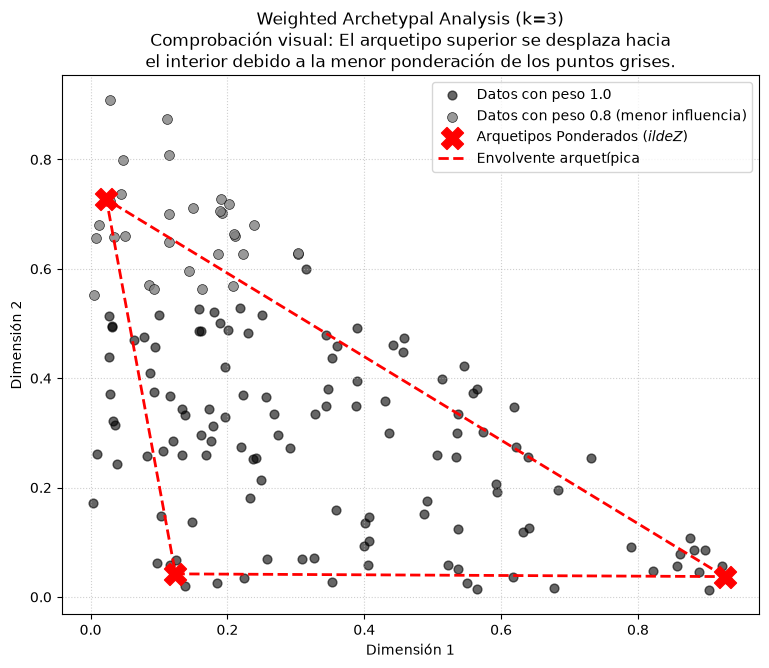

In [14]:
# ============================================================
# PRUEBA GRÁFICA (Simulando la Figura 3 del artículo)
# ============================================================

if __name__ == "__main__":
    rng = np.random.default_rng(42)

    # 1. Crear datos sintéticos 2D basados en 3 arquetipos verdaderos
    true_Z = np.array([
        [0.0, 0.0],
        [1.0, 0.0],
        [0.0, 1.0]
    ])

    n_samples = 150
    true_S = rng.dirichlet(np.ones(3), size=n_samples)
    X = true_S @ true_Z

    # 2. Definir pesos W (Matriz diagonal)
    # Simulamos el caso del artículo donde un subconjunto de puntos 
    # (por ejemplo, los cercanos a uno de los vértices) tienen menor peso (0.8)
    # y el resto peso estándar (1.0).
    weights = np.ones(n_samples)
    
    # Identificamos los puntos cercanos al arquetipo [0.0, 1.0] (tercera esquina)
    distances_to_corner = np.linalg.norm(X - np.array([0.0, 1.0]), axis=1)
    lower_weight_indices = np.argsort(distances_to_corner)[:30] # Los 30 más cercanos
    
    weights[lower_weight_indices] = 0.8  # Menor peso (ej: 0.8)
    W = np.diag(weights)

    # 3. Ejecutar Weighted Archetypal Analysis
    p = 3
    C, S, Z, history, selected = weighted_archetypal_analysis(
        X,
        p=p,
        W=W,
        max_iter=100,
        verbose=True
    )

    # 4. Generar la Gráfica de Comprobación (Estilo Figura 3)
    plt.figure(figsize=(9, 7))

    # Separar visualmente los puntos según su peso
    normal_mask = weights == 1.0
    lower_mask = weights < 1.0

    # Dibujar puntos con peso 1.0 (negros/oscuros)
    plt.scatter(
        X[normal_mask, 0], X[normal_mask, 1],
        c="black", alpha=0.6, s=40,
        label="Datos con peso 1.0"
    )

    # Dibujar puntos con menor peso (grises/claros, ej: 0.8)
    plt.scatter(
        X[lower_mask, 0], X[lower_mask, 1],
        c="gray", alpha=0.8, s=50, edgecolors="k", linewidths=0.5,
        label="Datos con peso 0.8 (menor influencia)"
    )

    # Dibujar Arquetipos Encontrados
    plt.scatter(
        Z[:, 0], Z[:, 1],
        c="red", s=250, marker="X",
        label="Arquetipos Ponderados ($\tilde{Z}$)"
    )

    # Trazar la envolvente arquetípica
    Z_polygon = np.vstack([Z, Z[0]])
    plt.plot(
        Z_polygon[:, 0], Z_polygon[:, 1],
        "r--", linewidth=2,
        label="Envolvente arquetípica"
    )

    plt.title(
        f"Weighted Archetypal Analysis (k={p})\n"
        f"Comprobación visual: El arquetipo superior se desplaza hacia\n"
        f"el interior debido a la menor ponderación de los puntos grises."
    )
    plt.xlabel("Dimensión 1")
    plt.ylabel("Dimensión 2")
    plt.legend(loc="upper right")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.show()